# Experiment 10: Document Similarity Analysis Using Shingling and LSH

**Aim:** To identify and evaluate document similarity using Shingling and Locality Sensitive Hashing (LSH).

**Mapped CO(s):** CO3


## 1. Import Required Libraries


In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd
from datasketch import MinHash, MinHashLSH

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 120)
print("Libraries imported")


Libraries imported


## 2. Load the Document Collection

Five short documents are used. D1 is written to be close to D2, and D3 is written to be close to D4. D5 is about a different topic.


In [2]:
documents = {
    "D1": "data science uses statistics and machine learning to analyze large data",
    "D2": "data science uses statistics and machine learning to analyze big data",
    "D3": "the football team scored many goals in the stadium during the match",
    "D4": "the football team scored many goals in the stadium during the game",
    "D5": "boiling pasta in salted water with tomatoes makes a simple dinner",
}
doc_df = pd.DataFrame({"Document ID": list(documents), "Text": list(documents.values())})
print("Documents loaded successfully")
print("Count:", len(documents))
doc_df


Documents loaded successfully
Count: 5


,Document ID,Text
0,D1,data science uses statistics and machine learning to analyze large data
1,D2,data science uses statistics and machine learning to analyze big data
2,D3,the football team scored many goals in the stadium during the match
3,D4,the football team scored many goals in the stadium during the game
4,D5,boiling pasta in salted water with tomatoes makes a simple dinner


## 3. Generate Shingles

A word shingle of size k is k consecutive words. Each document is stored as a set of shingles, so repeated shingles count once. The default size in this experiment is k = 2.


In [3]:
def tokens(text):
    return re.findall(r"[a-z]+", text.lower())


def shingles(text, k):
    words = tokens(text)
    return {" ".join(words[i:i + k]) for i in range(len(words) - k + 1)}


K = 2
shingle_sets = {doc_id: shingles(text, K) for doc_id, text in documents.items()}
shingle_summary = pd.DataFrame({
    "Document ID": list(shingle_sets),
    "Shingle count": [len(values) for values in shingle_sets.values()],
    "Shingles": [", ".join(sorted(values)) for values in shingle_sets.values()],
})
print(f"Shingle sets created with k = {K}")
shingle_summary


Shingle sets created with k = 2


,Document ID,Shingle count,Shingles
0,D1,10,"analyze large, and machine, data science, large data, learning to, machine learning, s..."
1,D2,10,"analyze big, and machine, big data, data science, learning to, machine learning, scien..."
2,D3,11,"during the, football team, goals in, in the, many goals, scored many, stadium during, ..."
3,D4,11,"during the, football team, goals in, in the, many goals, scored many, stadium during, ..."
4,D5,10,"a simple, boiling pasta, in salted, makes a, pasta in, salted water, simple dinner, to..."


## 4. Jaccard Similarity

Jaccard similarity of two sets is the size of their intersection divided by the size of their union. A score of 1 means the shingle sets are identical. A score of 0 means they share nothing.


Jaccard similarity between every pair (k = 2)


,D1,D2,D3,D4,D5
D1,1.000,0.667,0.000,0.000,0.0
D2,0.667,1.000,0.000,0.000,0.0
D3,0.000,0.000,1.000,0.833,0.0
D4,0.000,0.000,0.833,1.000,0.0
D5,0.000,0.000,0.000,0.000,1.0


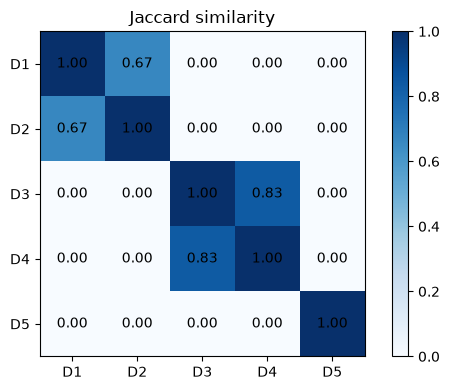

In [4]:
def jaccard(left, right):
    union = left | right
    if not union:
        return 1.0
    return len(left & right) / len(union)


ids = list(documents)
similarity = pd.DataFrame(index=ids, columns=ids, dtype=float)
for left in ids:
    for right in ids:
        similarity.loc[left, right] = round(jaccard(shingle_sets[left], shingle_sets[right]), 3)

print("Jaccard similarity between every pair (k = 2)")
display(similarity)

fig, ax = plt.subplots(figsize=(6, 4))
image = ax.imshow(similarity.astype(float), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(ids)), ids)
ax.set_yticks(range(len(ids)), ids)
ax.set_title("Jaccard similarity")
for row in range(len(ids)):
    for col in range(len(ids)):
        ax.text(col, row, f"{similarity.iloc[row, col]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()


## 5. MinHash Signatures and the LSH Index

MinHash compresses each shingle set into a short signature. The chance that two signatures agree is the Jaccard similarity. LSH places similar signatures in the same bucket, so a query does not have to be compared with every document.


In [5]:
NUM_PERM = 128
THRESHOLD = 0.5


def signature(shingle_set):
    hasher = MinHash(num_perm=NUM_PERM)
    for shingle in shingle_set:
        hasher.update(shingle.encode("utf-8"))
    return hasher


signatures = {doc_id: signature(values) for doc_id, values in shingle_sets.items()}
lsh = MinHashLSH(threshold=THRESHOLD, num_perm=NUM_PERM)
for doc_id, hasher in signatures.items():
    lsh.insert(doc_id, hasher)

print("MinHash signatures created. Permutations:", NUM_PERM)
print("LSH index created. Threshold:", THRESHOLD)
print()
print("Estimated Jaccard from MinHash, next to the exact score")
estimate_rows = []
for left in ids:
    for right in ids:
        if left < right:
            estimate_rows.append({
                "Pair": f"{left}-{right}",
                "Exact Jaccard": round(jaccard(shingle_sets[left], shingle_sets[right]), 3),
                "MinHash estimate": round(signatures[left].jaccard(signatures[right]), 3),
            })
pd.DataFrame(estimate_rows)


MinHash signatures created. Permutations: 128
LSH index created. Threshold: 0.5

Estimated Jaccard from MinHash, next to the exact score


,Pair,Exact Jaccard,MinHash estimate
0,D1-D2,0.667,0.586
1,D1-D3,0.000,0.000
2,D1-D4,0.000,0.000
3,D1-D5,0.000,0.000
4,D2-D3,0.000,0.000
5,D2-D4,0.000,0.000
6,D2-D5,0.000,0.000
7,D3-D4,0.833,0.781
8,D3-D5,0.000,0.000
9,D4-D5,0.000,0.000


## 6. Query Similar Documents


In [6]:
query_rows = []
for doc_id, hasher in signatures.items():
    matches = sorted(match for match in lsh.query(hasher) if match != doc_id)
    query_rows.append({"Query": doc_id, "Similar documents": ", ".join(matches) if matches else "(none)"})
query_df = pd.DataFrame(query_rows)
print("Documents returned by LSH at threshold 0.5")
query_df


Documents returned by LSH at threshold 0.5


,Query,Similar documents
0,D1,D2
1,D2,D1
2,D3,D4
3,D4,D3
4,D5,(none)


---
## Exercises / Assignments


### Exercise 1: Compute the Jaccard Similarity between two different documents


In [7]:
pair = ("D1", "D2")
left, right = pair
shared = shingle_sets[left] & shingle_sets[right]
only_left = shingle_sets[left] - shingle_sets[right]
only_right = shingle_sets[right] - shingle_sets[left]
score = jaccard(shingle_sets[left], shingle_sets[right])
print(f"Jaccard({left}, {right}) = {len(shared)} / {len(shared | only_left | only_right)} = {score:.3f}")
print("Shared shingles:", ", ".join(sorted(shared)))
print("Only in", left, ":", ", ".join(sorted(only_left)) or "(none)")
print("Only in", right, ":", ", ".join(sorted(only_right)) or "(none)")
print(f"Jaccard(D1, D5) = {jaccard(shingle_sets['D1'], shingle_sets['D5']):.3f} (unrelated topics)")


Jaccard(D1, D2) = 8 / 12 = 0.667
Shared shingles: and machine, data science, learning to, machine learning, science uses, statistics and, to analyze, uses statistics
Only in D1 : analyze large, large data
Only in D2 : analyze big, big data
Jaccard(D1, D5) = 0.000 (unrelated topics)


### Exercise 2: Change the shingle size and observe its effect on similarity


In [8]:
focus_pairs = [("D1", "D2"), ("D3", "D4"), ("D1", "D3"), ("D1", "D5")]
size_rows = []
for k in (1, 2, 3):
    sets_k = {doc_id: shingles(text, k) for doc_id, text in documents.items()}
    row = {"k": k}
    for left, right in focus_pairs:
        row[f"{left}-{right}"] = round(jaccard(sets_k[left], sets_k[right]), 3)
    size_rows.append(row)
size_df = pd.DataFrame(size_rows).set_index("k")
print("A larger shingle is stricter: one changed word removes more overlapping shingles.")
size_df


A larger shingle is stricter: one changed word removes more overlapping shingles.


,D1-D2,D3-D4,D1-D3,D1-D5
k,,,,
1,0.818,0.818,0.0,0.0
2,0.667,0.833,0.0,0.0
3,0.636,0.818,0.0,0.0


### Exercise 3: Add a new document and identify its similar documents using LSH


In [9]:
new_id = "D6"
new_text = "data science uses statistics and machine learning to study large data"
new_set = shingles(new_text, K)
new_signature = signature(new_set)
lsh.insert(new_id, new_signature)
matches = sorted(match for match in lsh.query(new_signature) if match != new_id)
print("Added document:", new_text)
print("LSH matches for D6:", ", ".join(matches) if matches else "(none)")
print("Exact Jaccard with each existing document:")
for doc_id in ids:
    print(f"  {doc_id}: {jaccard(new_set, shingle_sets[doc_id]):.3f}")


Added document: data science uses statistics and machine learning to study large data
LSH matches for D6: D1, D2
Exact Jaccard with each existing document:
  D1: 0.667
  D2: 0.538
  D3: 0.000
  D4: 0.000
  D5: 0.000


### Exercise 4: Compare the results obtained using different similarity thresholds


In [10]:
def query_at(threshold):
    index = MinHashLSH(threshold=threshold, num_perm=NUM_PERM)
    stored = dict(signatures)
    stored[new_id] = new_signature
    for doc_id, hasher in stored.items():
        index.insert(doc_id, hasher)
    rows = []
    for doc_id, hasher in stored.items():
        matches = sorted(match for match in index.query(hasher) if match != doc_id)
        rows.append({"Query": doc_id, f"threshold {threshold}": ", ".join(matches) if matches else "(none)"})
    return pd.DataFrame(rows).set_index("Query")


threshold_df = query_at(0.3).join(query_at(0.5)).join(query_at(0.8))
print("A lower threshold returns more candidates. A higher threshold keeps only very close matches.")
print("At 0.8 every query is empty. The MinHash estimates are 0.586 for D1-D2 and 0.781 for D3-D4,")
print("both below 0.8, even though the exact Jaccard score of D3-D4 is 0.833. LSH is approximate.")
threshold_df


A lower threshold returns more candidates. A higher threshold keeps only very close matches.
At 0.8 every query is empty. The MinHash estimates are 0.586 for D1-D2 and 0.781 for D3-D4,
both below 0.8, even though the exact Jaccard score of D3-D4 is 0.833. LSH is approximate.


,threshold 0.3,threshold 0.5,threshold 0.8
Query,,,
D1,"D2, D6","D2, D6",(none)
D2,"D1, D6","D1, D6",(none)
D3,D4,D4,(none)
D4,D3,D3,(none)
D5,(none),(none),(none)
D6,"D1, D2","D1, D2",(none)


### Exercise 5: Explain the advantages of LSH over direct document comparison

Direct comparison computes Jaccard similarity for every pair. With n documents that is about n squared comparisons, and each comparison walks through the shingle sets.

LSH does not replace the similarity score. It avoids most of those comparisons:

- MinHash stores a fixed-length signature instead of the full shingle set.
- Documents whose signatures land in the same bucket are the only candidates.
- A query checks those candidates, not the whole collection.

That matters when the collection is large, as in duplicate detection or a search engine. On these six short documents the exact pairs and the LSH candidates agree, which is what the threshold is for: pairs above it should be found, and unrelated pairs should be skipped.


---
## Observation

- Shingle sets were created for every document.
- Jaccard similarity was high for D1-D2 and D3-D4, and zero for documents on different topics.
- MinHash estimates stayed close to the exact Jaccard scores.
- The LSH index returned the similar document for each query and skipped the unrelated ones.
- Threshold 0.3 and 0.5 returned the similar pairs. Threshold 0.8 returned none, because the MinHash estimates fell below 0.8. LSH can miss a truly similar pair when the threshold is set above the estimated score.

## Result

Document similarity was measured with shingling and Jaccard similarity, then retrieved with MinHash and LSH. Similar documents were found without comparing every pair by hand.

## Conclusion

Shingling turns a document into a set, and Jaccard similarity scores that set against another document. LSH uses MinHash signatures to find likely matches quickly. The same idea is used for near-duplicate detection, plagiarism checks, and search.
